# XGBoost Pan-Cancer Multi-Omics Classification (GPU)

Faithful, self-contained port of `Final/XGBoost_ SVM_RF_LR.ipynb` for **xgboost 3.x**.
The original used `tree_method='gpu_hist'` / `predictor='gpu_predictor'`, which were
removed in xgboost 3.x. Here we use the modern equivalent:
`tree_method='hist'` + `device='cuda'`, with automatic CPU fallback.

- Task: 32-class pan-cancer type classification (labels 0-31)
- Data: 8314 samples x 9844 features (3217 mRNA + 383 miRNA + 3105 CNV + 3139 methylation)
- Kernel: **xgb-venv** = Python 3.13 (GPU venv with xgboost 3.4.1)
- Verified GPU: NVIDIA RTX 4060 (driver 610.47, CUDA 13.3)

Run all cells top-to-bottom. Outputs are written to this folder.


In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd


## 1. Data paths

In [2]:
# Use the notebook's own folder first (self-contained), then env var / fallback
import pathlib
_nb_dir = str(pathlib.Path().resolve())
DATA_DIR = _nb_dir
if not os.path.exists(os.path.join(DATA_DIR, 'Pan-cancer_mRNA.csv')):
    DATA_DIR = os.environ.get('DATA_DIR', r'D:\\Test_XGboost')

cancer = 'Pan-cancer'
file_map = {
    'mRNA':  os.path.join(DATA_DIR, f'{cancer}_mRNA.csv'),
    'miRNA': os.path.join(DATA_DIR, f'{cancer}_miRNA.csv'),
    'CNV':   os.path.join(DATA_DIR, f'{cancer}_CNV.csv'),
    'Methy': os.path.join(DATA_DIR, f'{cancer}_Methy.csv'),
    'label': os.path.join(DATA_DIR, f'{cancer}_label_num.csv'),
}

for k, v in file_map.items():
    if not os.path.exists(v):
        print(f'WARNING: missing {v}')
    else:
        print(f'OK: {k} -> {os.path.basename(v)}')


OK: mRNA -> Pan-cancer_mRNA.csv
OK: miRNA -> Pan-cancer_miRNA.csv
OK: CNV -> Pan-cancer_CNV.csv
OK: Methy -> Pan-cancer_Methy.csv
OK: label -> Pan-cancer_label_num.csv


## 2. Load & preprocess

- Read the 4 omics CSVs (`index_col=0`), transpose so rows = TCGA samples
- Add a `_mRNA/_miRNA/_CNV/_Methy` suffix per modality for feature provenance
- Inner-join on sample IDs so only samples present in all 4 modalities remain
- Positionally re-align labels if the index does not match
- Mean-impute NaNs (the MLOmics dataset is already mean-imputed by its authors)


In [3]:
omics_file_1 = pd.read_csv(file_map["mRNA"], index_col=0)
omics_file_2 = pd.read_csv(file_map["miRNA"], index_col=0)
omics_file_3 = pd.read_csv(file_map["CNV"], index_col=0)
omics_file_4 = pd.read_csv(file_map["Methy"], index_col=0)
labels_df = pd.read_csv(file_map["label"], header=0)

omics_data_1 = omics_file_1.T.add_suffix("_mRNA")
omics_data_2 = omics_file_2.T.add_suffix("_miRNA")
omics_data_3 = omics_file_3.T.add_suffix("_CNV")
omics_data_4 = omics_file_4.T.add_suffix("_Methy")

omics_data_combined = (
    omics_data_1.join(omics_data_2, how="inner")
    .join(omics_data_3, how="inner")
    .join(omics_data_4, how="inner")
)
print(f"Samples after inner-join: {omics_data_combined.shape[0]}  | Features: {omics_data_combined.shape[1]}")

if "Label" in labels_df.columns:
    labels = labels_df["Label"]
else:
    labels = labels_df.iloc[:, 0]

if not labels.index.equals(omics_data_combined.index):
    if len(labels) == len(omics_data_combined):
        labels = pd.Series(labels.values, index=omics_data_combined.index, name="Label")
    else:
        common_idx = labels.index.intersection(omics_data_combined.index)
        omics_data_combined = omics_data_combined.loc[common_idx]
        labels = labels.loc[common_idx]
print(f"Samples with labels after alignment: {len(labels)}  | Classes: {labels.nunique()}")

omics_data_combined = omics_data_combined.apply(pd.to_numeric, errors="coerce")
omics_data_combined = omics_data_combined.fillna(omics_data_combined.mean())
print("Missing values after imputation:", int(omics_data_combined.isna().sum().sum()))


Samples after inner-join: 8314  | Features: 9844
Samples with labels after alignment: 8314  | Classes: 32


Missing values after imputation: 0


## 3. Train/test split + scaling

Stratified 80/20 split (`random_state=42`), `StandardScaler` fit on the training
set only (no test-set leakage).


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    omics_data_combined, labels, test_size=0.2, random_state=42, stratify=labels
)
print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Train: 6651 | Test: 1663


## 4. Models

**XGBoost** uses `device='cuda'` on your RTX 4060 with automatic CPU fallback.
Config mirrors the original notebook: `max_depth=6, lr=0.1, subsample=0.8,
colsample_bytree=0.8, random_state=42`.


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import xgboost as xgb


def make_xgb(n_estimators):
    """XGBoost on GPU (device='cuda') with CPU fallback."""
    probe = xgb.XGBClassifier(n_estimators=1, max_depth=1,
                              tree_method="hist", device="cuda", random_state=42)
    try:
        probe.fit(np.random.rand(16, 4), np.random.randint(0, 2, 16))
        print("XGBoost: CUDA device available.")
        return xgb.XGBClassifier(
            n_estimators=n_estimators, max_depth=6, learning_rate=0.1,
            subsample=0.8, colsample_bytree=0.8,
            tree_method="hist", device="cuda", random_state=42, n_jobs=1,
        )
    except Exception:
        print("CUDA not available; using CPU.")
        return xgb.XGBClassifier(
            n_estimators=n_estimators, max_depth=6, learning_rate=0.1,
            subsample=0.8, colsample_bytree=0.8,
            tree_method="hist", random_state=42, n_jobs=1,
        )


models = {
    "XGBoost": make_xgb(300),
    "SVM": SVC(kernel="linear", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42, n_jobs=-1, solver="lbfgs"),
}


XGBoost: CUDA device available.


## 5. Holdout test-set evaluation (80/20 split)

Metrics: weighted precision, NMI, ARI, wall-clock training time.


In [6]:
from sklearn.metrics import precision_score, normalized_mutual_info_score, adjusted_rand_score


def evaluate_model(model, Xtr, Xte, ytr, yte):
    start = time.time()
    model.fit(Xtr, ytr)
    y_pred = model.predict(Xte)
    dur = time.time() - start
    return (
        precision_score(yte, y_pred, average="weighted", zero_division=0),
        normalized_mutual_info_score(yte, y_pred),
        adjusted_rand_score(yte, y_pred),
        dur,
    )


results = {}
for name, model in models.items():
    prec, nmi, ari, dur = evaluate_model(model, X_train_scaled, X_test_scaled, y_train, y_test)
    results[name] = (prec, nmi, ari, dur)
    print(f"{name:<20} prec={prec:.4f}  nmi={nmi:.4f}  ari={ari:.4f}  time={dur:.1f}s")


XGBoost              prec=0.9783  nmi=0.9730  ari=0.9709  time=191.5s


SVM                  prec=0.9702  nmi=0.9635  ari=0.9580  time=23.7s


Random Forest        prec=0.9589  nmi=0.9570  ari=0.9403  time=8.2s


Logistic Regression  prec=0.9644  nmi=0.9594  ari=0.9532  time=2.5s


## 6. 5-fold stratified cross-validation

`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`; each pipeline applies
`StandardScaler` *inside* the fold. XGBoost uses 200 trees here (as in the original).


In [7]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, cohen_kappa_score, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X = omics_data_combined
y = labels

# REVIEWER COMMENT 1: cross-validation is restricted to the 80% TRAINING
# partition so the 20% holdout stays untouched until final evaluation.
print(f"CV scope: training partition only -> {X_train.shape[0]} samples "
      f"(holdout of {X_test.shape[0]} samples reserved for final evaluation)")

pipelines = {
    "XGBoost": Pipeline([("scaler", StandardScaler()), ("clf", make_xgb(200))]),
    "SVM": Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="linear", random_state=42))]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=2)),
    ]),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=42, n_jobs=1, solver="lbfgs")),
    ]),
}

scoring = {
    "precision_weighted": "precision_weighted",
    "f1_weighted": "f1_weighted",
    "accuracy": "accuracy",
    "kappa": make_scorer(cohen_kappa_score),
    "macro_f1": make_scorer(f1_score, average="macro"),
}

cv_results = []
for name, pipeline in pipelines.items():
    print(f"Running 5-fold CV for {name}...")
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring,
                            return_train_score=False, n_jobs=1)
    row = {"model": name}
    for k in scoring:
        row[f"cv_mean_{k}"] = round(float(scores[f"test_{k}"].mean()), 5)
        row[f"cv_std_{k}"] = round(float(scores[f"test_{k}"].std(ddof=1)), 5)
    cv_results.append(row)
    print(f"{name:<20} acc={row['cv_mean_accuracy']:.4f}  f1={row['cv_mean_f1_weighted']:.4f}  "
          f"macroF1={row['cv_mean_macro_f1']:.4f}  kappa={row['cv_mean_kappa']:.4f}")

cv_df = pd.DataFrame(cv_results)
import pathlib
_REPO = pathlib.Path.cwd()
if not (_REPO / "results").exists() and (_REPO.parent / "results").exists():
    _REPO = _REPO.parent
RES = _REPO / "results"
RES.mkdir(parents=True, exist_ok=True)
(RES / "metrics").mkdir(parents=True, exist_ok=True)
cv_df.to_csv(RES / "metrics" / "cv_4models.csv", index=False)
print("\nSaved", RES / "metrics" / "cv_4models.csv")
cv_df.round(4)


CV scope: training partition only -> 6651 samples (holdout of 1663 samples reserved for final evaluation)
XGBoost: CUDA device available.
Running 5-fold CV for XGBoost...


XGBoost              acc=0.9725  f1=0.9719  macroF1=0.9443  kappa=0.9711
Running 5-fold CV for SVM...


SVM                  acc=0.9663  f1=0.9656  macroF1=0.9405  kappa=0.9647
Running 5-fold CV for Random Forest...


Random Forest        acc=0.9505  f1=0.9461  macroF1=0.8936  kappa=0.9481
Running 5-fold CV for Logistic Regression...


Logistic Regression  acc=0.9626  f1=0.9618  macroF1=0.9290  kappa=0.9607

Saved D:\ICBEA-2027-PanCancer-MultiOmics\results\metrics\cv_4models.csv


,model,cv_mean_precision_weighted,cv_std_precision_weighted,cv_mean_f1_weighted,cv_std_f1_weighted,cv_mean_accuracy,cv_std_accuracy,cv_mean_kappa,cv_std_kappa,cv_mean_macro_f1,cv_std_macro_f1
0,XGBoost,0.9730,0.0028,0.9719,0.0030,0.9725,0.0029,0.9712,0.0030,0.9443,0.0180
1,SVM,0.9665,0.0044,0.9656,0.0045,0.9663,0.0044,0.9647,0.0046,0.9405,0.0182
2,Random Forest,0.9528,0.0059,0.9461,0.0049,0.9505,0.0050,0.9481,0.0053,0.8936,0.0123
3,Logistic Regression,0.9624,0.0059,0.9618,0.0058,0.9626,0.0056,0.9608,0.0058,0.9290,0.0206


## 7. Confusion matrices (cross-validated predictions)

XGBoost              precision=0.9725 recall=0.9725 f1=0.9720


SVM                  precision=0.9664 recall=0.9663 f1=0.9659


Random Forest        precision=0.9528 recall=0.9505 f1=0.9463


Logistic Regression  precision=0.9623 recall=0.9626 f1=0.9620


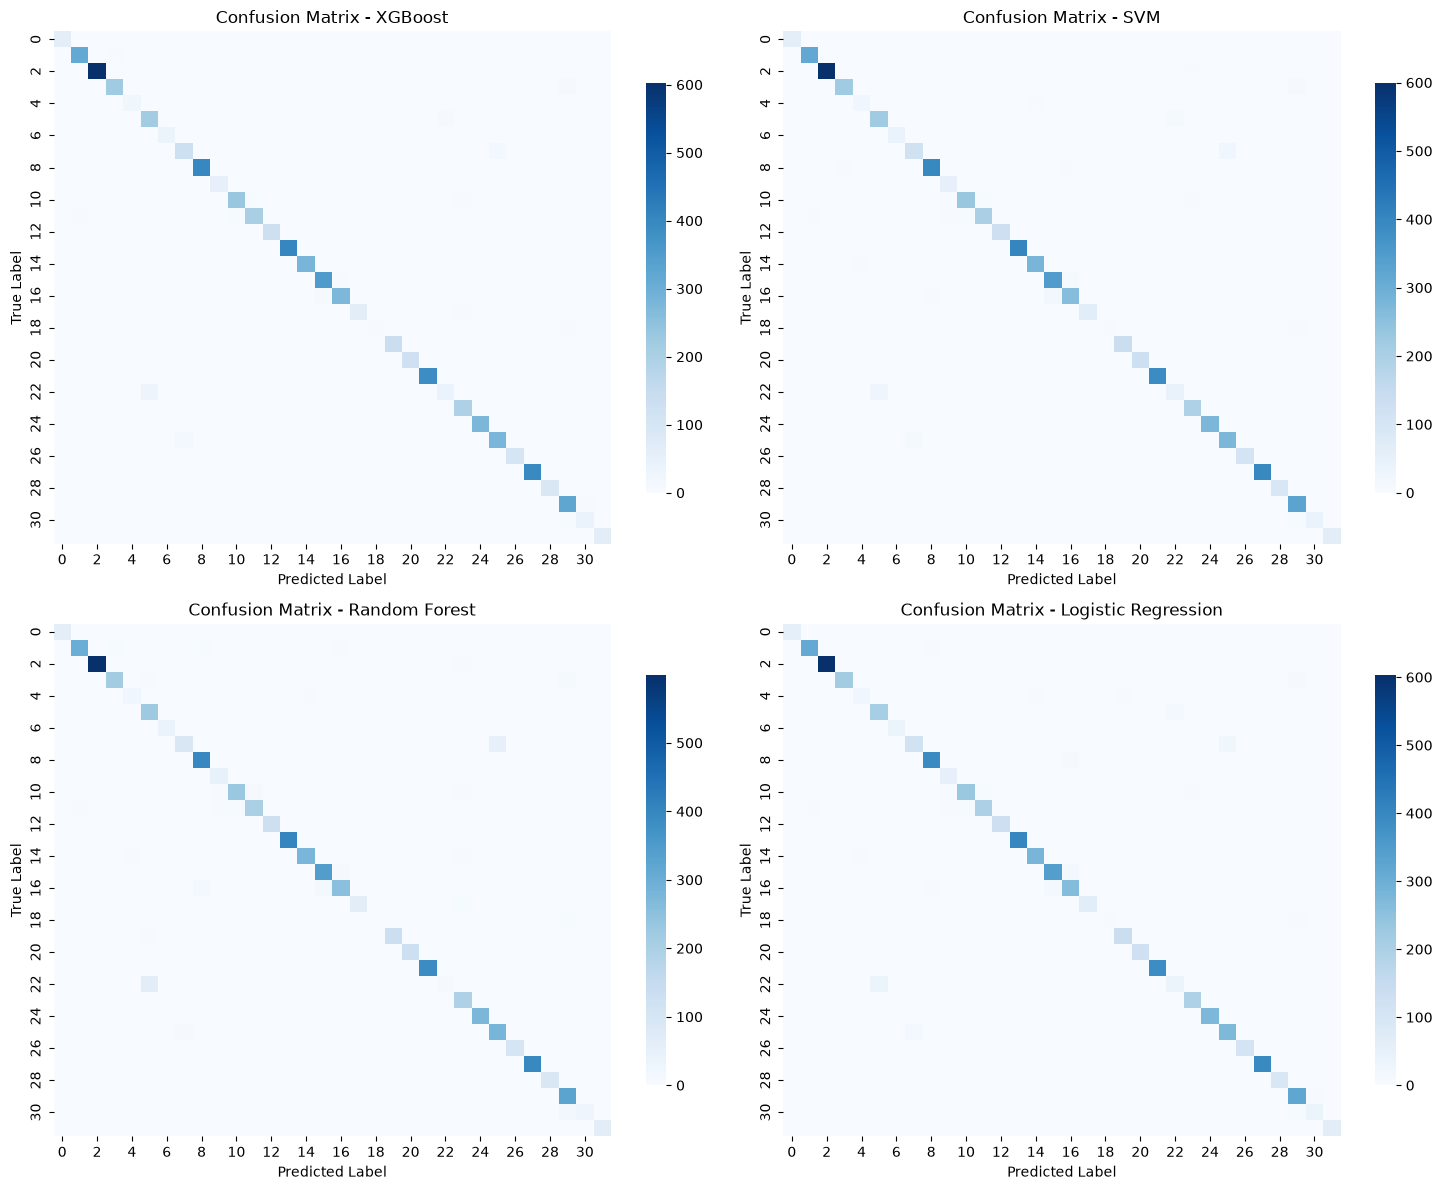

Saved D:\ICBEA-2027-PanCancer-MultiOmics\results\figures\confusion_matrices_5fold.png


In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib
_REPO = pathlib.Path.cwd()
if not (_REPO / "results").exists() and (_REPO.parent / "results").exists():
    _REPO = _REPO.parent
RES = _REPO / "results"
RES.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

for idx, (name, pipeline) in enumerate(pipelines.items()):
    # CV predictions on the TRAINING partition only (holdout untouched)
    y_pred_cv = cross_val_predict(pipeline, X_train, y_train, cv=cv, n_jobs=1)
    cm = confusion_matrix(y_train, y_pred_cv)
    sns.heatmap(cm, annot=False, fmt="d", cmap="Blues", ax=axes[idx],
                cbar_kws={"shrink": 0.8})
    axes[idx].set_title(f"Confusion Matrix - {name}")
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

    report = classification_report(y_train, y_pred_cv, output_dict=True)
    wa = report["weighted avg"]
    print(f"{name:<20} precision={wa['precision']:.4f} recall={wa['recall']:.4f} f1={wa['f1-score']:.4f}")

plt.tight_layout()
(RES / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(RES / "figures" / "confusion_matrices_5fold.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved", RES / "figures" / "confusion_matrices_5fold.png")


## 8. Consistency analysis

Consistency = `1 - (precision_std / precision_mean)` (higher = more stable across folds).


In [9]:
print("Fold consistency = 1 - std/mean (higher = more consistent across folds)")
print("Cross-validation is computed within the 80% training partition only.\n")
for row in cv_results:
    consistency = 1 - (row["cv_std_precision_weighted"] / row["cv_mean_precision_weighted"])
    cv_pct = row["cv_std_precision_weighted"] / row["cv_mean_precision_weighted"] * 100
    print(f"{row['model']:<20} consistency={consistency:.4f}  (precision CV={cv_pct:.2f}%)")


Fold consistency = 1 - std/mean (higher = more consistent across folds)
Cross-validation is computed within the 80% training partition only.

XGBoost              consistency=0.9971  (precision CV=0.29%)
SVM                  consistency=0.9954  (precision CV=0.46%)
Random Forest        consistency=0.9938  (precision CV=0.62%)
Logistic Regression  consistency=0.9939  (precision CV=0.61%)


## 9. Interpretability — model checkpoint, feature importance, SHAP, ROC/PR

Reuses the XGBoost model already trained in §5 (`models["XGBoost"]`, 300 trees,
GPU). If that variable is gone (kernel restarted), re-run cells 1–5 first, or
re-load from the saved checkpoint with `xgb.XGBClassifier().load_model(...)`.


In [10]:
# 9a. Save model checkpoint + load checkpoint (round-trip check)
xgb_model = models["XGBoost"]
xgb_model.save_model("xgboost_model.json")
print("Saved xgboost_model.json")

check = xgb.XGBClassifier()
check.load_model("xgboost_model.json")
print("Checkpoint reload OK:", check.n_estimators, "trees, depth", check.max_depth)


Saved xgboost_model.json


Checkpoint reload OK: None trees, depth None


### 9b. Feature importance (gain)

Full importance saved to `feature_importance.csv`; top-20 bar plot to `feature_importance.png`.


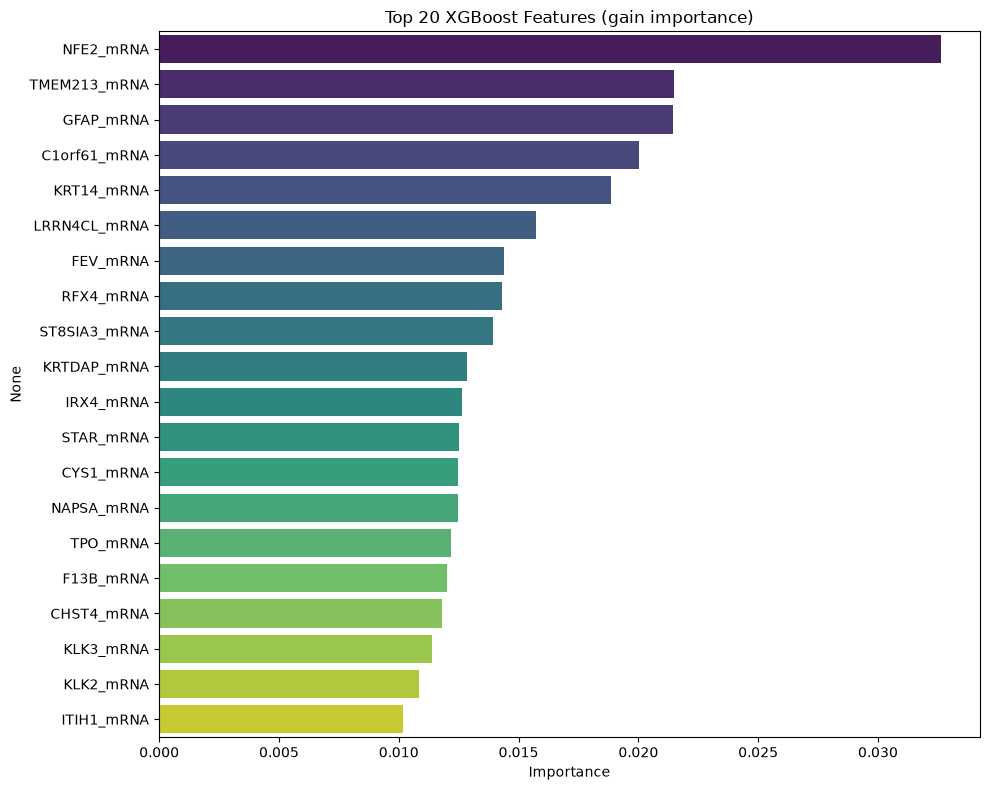

Saved feature_importance.csv / feature_importance.png
Top 5: ['NFE2_mRNA', 'TMEM213_mRNA', 'GFAP_mRNA', 'C1orf61_mRNA', 'KRT14_mRNA']


In [11]:
importance = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.to_csv("feature_importance.csv", header=["importance"])

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(x=importance.head(20).values, y=importance.head(20).index, ax=ax, palette="viridis")
ax.set_title("Top 20 XGBoost Features (gain importance)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved feature_importance.csv / feature_importance.png")
print("Top 5:", importance.head(5).index.tolist())


### 9c. SHAP analysis (TreeExplainer)

`shap` (0.52.0) is installed in the `xgb-venv` kernel. We explain a random
sample of 200 test patients (stratified, seed 42) for speed; multiclass SHAP
returns shape (samples, features, classes).


In [12]:
import shap

explainer = shap.TreeExplainer(xgb_model)
rng = np.random.RandomState(42)
n_sample = min(200, X_test_scaled.shape[0])
idx = rng.choice(X_test_scaled.shape[0], n_sample, replace=False)
X_shap = X_test_scaled[idx]
shap_values = np.asarray(explainer.shap_values(X_shap))
print("SHAP values shape:", shap_values.shape)  # (samples, features, classes)

# Aggregate: mean |SHAP| over samples x classes -> global feature ranking
mean_abs_shap = np.mean(np.abs(shap_values), axis=(0, 2))
shap_top = pd.Series(mean_abs_shap, index=X.columns).sort_values(ascending=False)
shap_top.to_csv("shap_top20.csv", header=["mean_abs_shap"])
print("Top 10 by mean |SHAP|:")
print(shap_top.head(10).to_string())


SHAP values shape: (200, 9844, 32)
Top 10 by mean |SHAP|:
GAGE12J_mRNA            0.078593
hsa-miR-206_miRNA       0.076341
hsa-miR-122-5p_miRNA    0.070800
SFTPA1_mRNA             0.054135
SFTPB_mRNA              0.045591
TG_mRNA                 0.044642
hsa-miR-30a-3p_miRNA    0.043567
GPA33_mRNA              0.039223
hsa-miR-205-5p_miRNA    0.039220
NKX3-1_mRNA             0.038223


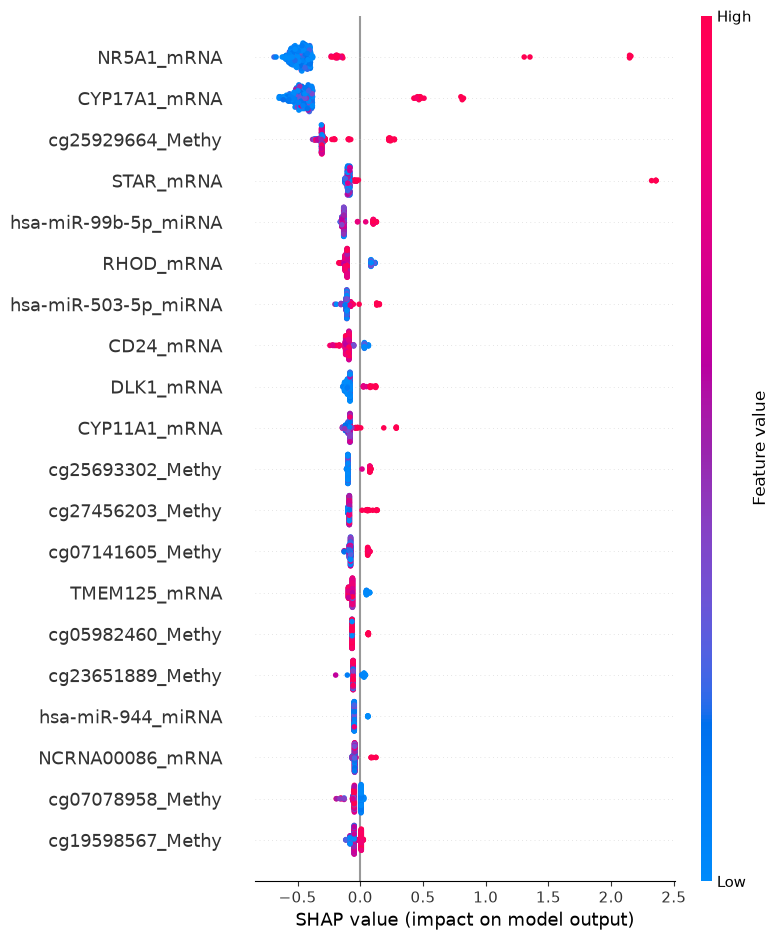

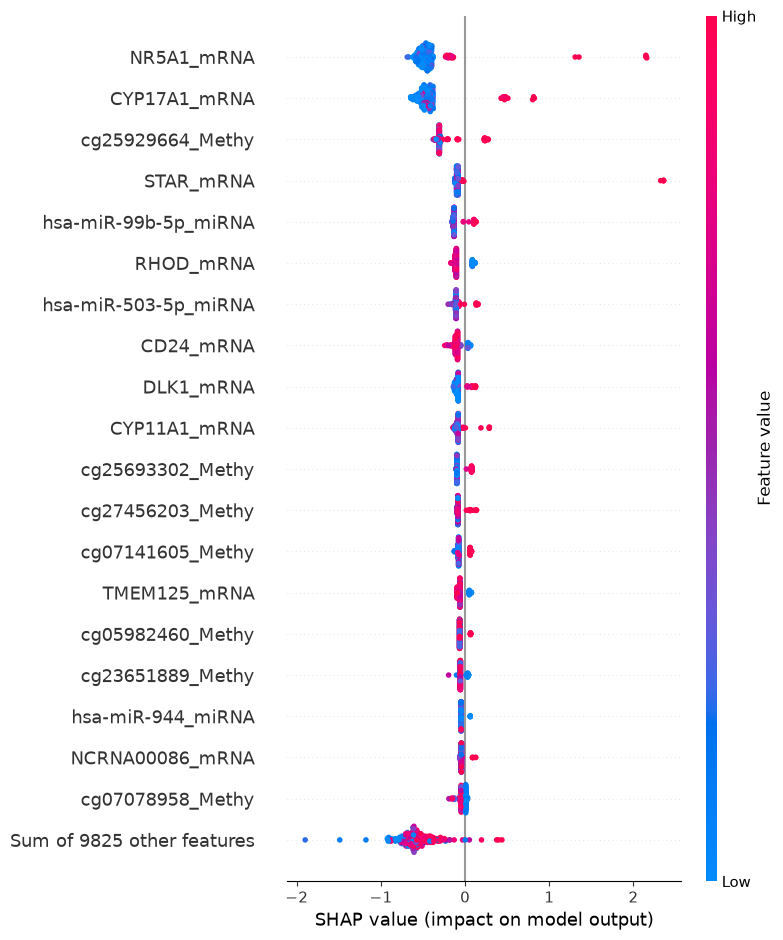

Saved shap_summary.png / shap_beeswarm.png / shap_top20.csv


In [13]:
# 9d. SHAP summary + beeswarm plots (class-0 SHAP values, top 20 features)
disp = shap_values[:, :, 0]  # 2D (samples, features) for class 0

fig, ax = plt.subplots(figsize=(10, 8))
shap.summary_plot(disp, X_shap, feature_names=X.columns.tolist(), show=False, max_display=20)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
shap.plots.beeswarm(shap.Explanation(values=disp, data=X_shap,
                                     feature_names=X.columns.tolist()),
                    max_display=20, show=False)
plt.tight_layout()
plt.savefig("shap_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved shap_summary.png / shap_beeswarm.png / shap_top20.csv")


### 9e. Multiclass ROC-AUC and Precision-Recall (one-vs-rest)

Macro-averaged across all 32 classes on the held-out test set.


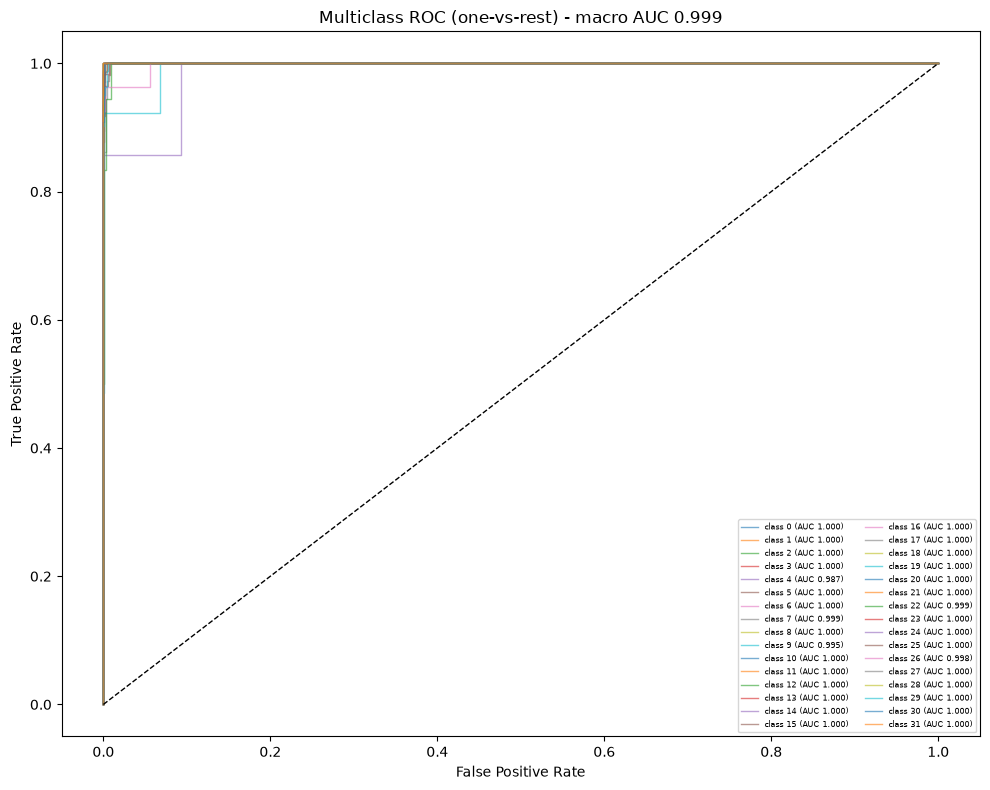

macro ROC AUC: 0.9992  -> roc_auc.png / roc_auc.csv


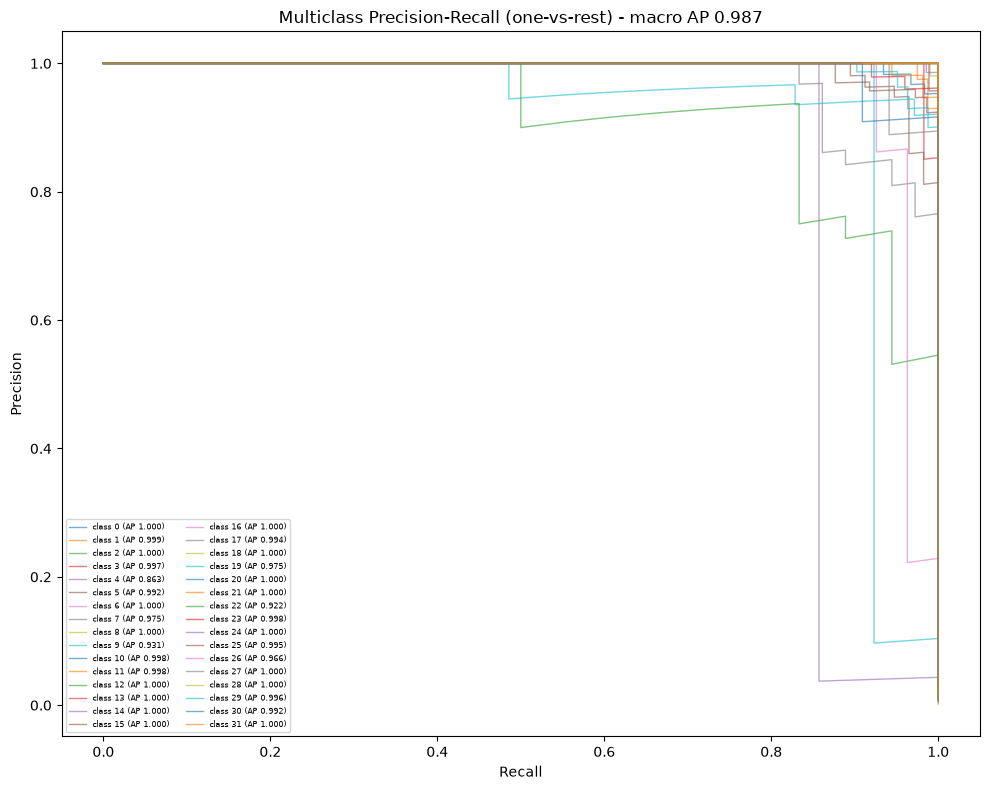

macro average precision: 0.9872  -> pr_curve.png / pr_curve.csv


In [14]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

y_true = y_test.values
probs = xgb_model.predict_proba(X_test_scaled)
n_classes = len(np.unique(y_true))

# --- ROC ---
roc_rows = []
fig, ax = plt.subplots(figsize=(10, 8))
for c in range(n_classes):
    fpr, tpr, _ = roc_curve((y_true == c).astype(int), probs[:, c])
    a = auc(fpr, tpr)
    roc_rows.append({"class": c, "auc": a, "n": int((y_true == c).sum())})
    ax.plot(fpr, tpr, lw=1, alpha=0.6, label=f"class {c} (AUC {a:.3f})")
macro_auc = float(np.mean([r["auc"] for r in roc_rows]))
roc_rows.append({"class": "macro", "auc": macro_auc, "n": len(y_true)})
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title(f"Multiclass ROC (one-vs-rest) - macro AUC {macro_auc:.3f}")
ax.legend(loc="lower right", fontsize=6, ncol=2)
plt.tight_layout(); plt.savefig("roc_auc.png", dpi=300, bbox_inches="tight"); plt.show()
pd.DataFrame(roc_rows).to_csv("roc_auc.csv", index=False)
print(f"macro ROC AUC: {macro_auc:.4f}  -> roc_auc.png / roc_auc.csv")

# --- Precision-Recall ---
pr_rows = []
fig, ax = plt.subplots(figsize=(10, 8))
for c in range(n_classes):
    p, r, _ = precision_recall_curve((y_true == c).astype(int), probs[:, c])
    ap = average_precision_score((y_true == c).astype(int), probs[:, c])
    pr_rows.append({"class": c, "ap": ap, "n": int((y_true == c).sum())})
    ax.plot(r, p, lw=1, alpha=0.6, label=f"class {c} (AP {ap:.3f})")
macro_ap = float(np.mean([r["ap"] for r in pr_rows]))
pr_rows.append({"class": "macro", "ap": macro_ap, "n": len(y_true)})
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title(f"Multiclass Precision-Recall (one-vs-rest) - macro AP {macro_ap:.3f}")
ax.legend(loc="lower left", fontsize=6, ncol=2)
plt.tight_layout(); plt.savefig("pr_curve.png", dpi=300, bbox_inches="tight"); plt.show()
pd.DataFrame(pr_rows).to_csv("pr_curve.csv", index=False)
print(f"macro average precision: {macro_ap:.4f}  -> pr_curve.png / pr_curve.csv")


## 10. INDICON 2026 revision experiments

Added for the mentor's requested revisions (statistical test + ablation + metrics + class mapping).
These reuse `omics_data_combined` / `labels` from §2–3 and the `make_xgb()` helper from §4.
Run in order; §10a must run before §10b–10d.


### 10a. Repeated 5-fold CV + Wilcoxon signed-rank test (XGBoost vs Logistic Regression)

Ma'am requested ≥ 6 paired observations. Repeated 5-fold CV gives 5×5 = **25 paired folds**.
Same folds, same scaler-per-fold → true pairing. Tests whether XGBoost is significantly
better than Logistic Regression (Wilcoxon signed-rank, one-sided 'greater').

In [15]:
from scipy import stats
import numpy as np

# ---------------------------------------------------------------------------
# RUNTIME NOTE
# The 25-fold repeated-CV retraining (XGBoost + SVM + LogisticRegression on
# 9,844 features) is implemented in `src/revision_experiments.py` and takes
# hours, dominated by the lbfgs LogisticRegression fits. Here we load the saved
# per-fold scores and recompute the corrected paired statistics, so this
# notebook stays runnable end-to-end.
# ---------------------------------------------------------------------------
import pathlib
_REPO = pathlib.Path.cwd()
if not (_REPO / "results").exists() and (_REPO.parent / "results").exists():
    _REPO = _REPO.parent
RES = _REPO / "results"
RES.mkdir(parents=True, exist_ok=True)

_p = RES / "statistical_analysis" / "paired_folds.csv"
assert _p.exists(), f"{_p} not found"
paired = pd.read_csv(_p)
print("Loaded paired folds:", _p, "| n =", len(paired))

METRICS = ["precision_weighted", "f1_weighted", "accuracy", "kappa", "macro_f1"]
J = len(paired)
DF = J - 1
NTT = 0.25            # 5-fold: test/train size ratio = 1/4

rows = []
for comp in ["svm", "lr"]:
    for k in METRICS:
        d = (paired[f"xgb_{k}"] - paired[f"{comp}_{k}"]).values
        mean, sd = d.mean(), d.std(ddof=1)
        se_nb = np.sqrt((1.0 / J + NTT) * sd ** 2)      # Nadeau-Bengio variance
        t_nb = mean / se_nb
        half = stats.t.ppf(0.975, DF) * se_nb
        p2 = 2 * stats.t.sf(abs(t_nb), DF)
        wr = stats.wilcoxon(paired[f"xgb_{k}"], paired[f"{comp}_{k}"])
        rows.append({
            "comparison": f"XGBoost_vs_{comp.upper()}", "metric": k, "n_paired": J,
            "xgb_mean": round(float(paired[f'xgb_{k}'].mean()), 5),
            f"{comp}_mean": round(float(paired[f'{comp}_{k}'].mean()), 5),
            "mean_delta": round(float(mean), 5), "sd_delta": round(float(sd), 5),
            "se_nadeau_bengio": round(float(se_nb), 6),
            "ci95_low": round(float(mean - half), 5),
            "ci95_high": round(float(mean + half), 5),
            "cohens_d": round(float(mean / sd), 3),
            "p_nb_two_sided": round(float(p2), 6),
            "p_wilcoxon_uncorrected": round(float(wr.pvalue), 6),
            "significant_5pct": "YES" if p2 < 0.05 else "no",
            "ci_consistent_with_p": "YES" if ((mean - half > 0) == (p2 < 0.05)) else "NO",
        })

sig = pd.DataFrame(rows)
sig.to_csv(RES / "statistical_analysis" / "significance_corrected.csv", index=False)
print("\nCorrected paired comparisons (Nadeau-Bengio, 25 folds):")
print(sig[["comparison", "metric", "mean_delta", "ci95_low", "ci95_high",
           "cohens_d", "p_nb_two_sided", "significant_5pct"]].to_string(index=False))
print("\nSaved", RES / "statistical_analysis" / "significance_corrected.csv")
print("NOTE: plain Wilcoxon p-values assume independent folds and are anti-conservative;")
print("      only the Nadeau-Bengio corrected values should be reported.")


Loaded paired folds: D:\ICBEA-2027-PanCancer-MultiOmics\results\statistical_analysis\paired_folds.csv | n = 25

Corrected paired comparisons (Nadeau-Bengio, 25 folds):
    comparison             metric  mean_delta  ci95_low  ci95_high  cohens_d  p_nb_two_sided significant_5pct
XGBoost_vs_SVM precision_weighted     0.00603   0.00151    0.01054     1.483        0.011051              YES
XGBoost_vs_SVM        f1_weighted     0.00599   0.00171    0.01028     1.554        0.008136              YES
XGBoost_vs_SVM           accuracy     0.00610   0.00197    0.01024     1.642        0.005510              YES
XGBoost_vs_SVM              kappa     0.00640   0.00207    0.01073     1.642        0.005509              YES
XGBoost_vs_SVM           macro_f1     0.00695  -0.01446    0.02835     0.361        0.509372               no
 XGBoost_vs_LR precision_weighted     0.00788   0.00296    0.01281     1.778        0.003000              YES
 XGBoost_vs_LR        f1_weighted     0.00771   0.00315    0.0

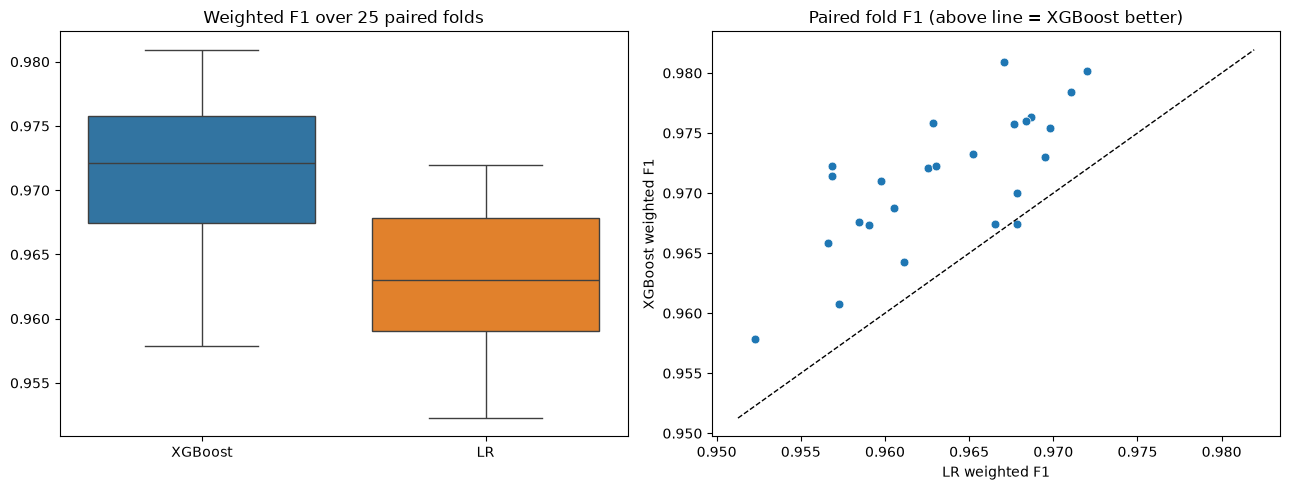

Saved paired_scores.png


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=paired[["xgb_f1_weighted", "lr_f1_weighted"]], ax=ax[0])
ax[0].set_title("Weighted F1 over 25 paired folds"); ax[0].set_xticklabels(["XGBoost", "LR"])
sns.scatterplot(data=paired, x="lr_f1_weighted", y="xgb_f1_weighted", ax=ax[1], s=40)
lo = min(paired.xgb_f1_weighted.min(), paired.lr_f1_weighted.min()) - 0.001
hi = max(paired.xgb_f1_weighted.max(), paired.lr_f1_weighted.max()) + 0.001
ax[1].plot([lo, hi], [lo, hi], "k--", lw=1)
ax[1].set_title("Paired fold F1 (above line = XGBoost better)")
ax[1].set_xlabel("LR weighted F1"); ax[1].set_ylabel("XGBoost weighted F1")
plt.tight_layout(); plt.savefig("paired_scores.png", dpi=300, bbox_inches="tight"); plt.show()
print("Saved paired_scores.png")


### 10c. mRNA-only ablation vs full multi-omics

Tests whether mRNA expression alone (3,217 features) preserves full-model (9,844)
performance — the mentor's direct question and the observation that all top-20 gain
features are mRNA lineage markers.

   configuration  n_features  holdout_accuracy  holdout_macro_f1  cv_accuracy  cv_macro_f1  cv_weighted_f1
full_multi_omics        9844            0.9778            0.9534       0.9725       0.9443          0.9719
    without_mRNA        6627            0.9790            0.9394       0.9681       0.9454          0.9675
   without_miRNA        9461            0.9681            0.9327       0.9645       0.9259          0.9633
     without_CNV        6739            0.9790            0.9569       0.9722       0.9479          0.9717
   without_Methy        6705            0.9705            0.9454       0.9657       0.9296          0.9646
       mRNA_only        3217            0.9603            0.9219       0.9547       0.9038          0.9531

Paired differences vs the full model (25 folds, Nadeau-Bengio corrected):
          comparison   metric  mean_delta            ci95_NB  p_NB_2s significant_5pct
 full - without_mRNA accuracy     0.00604 [+0.0021, +0.0100]  0.00445              YES
fu

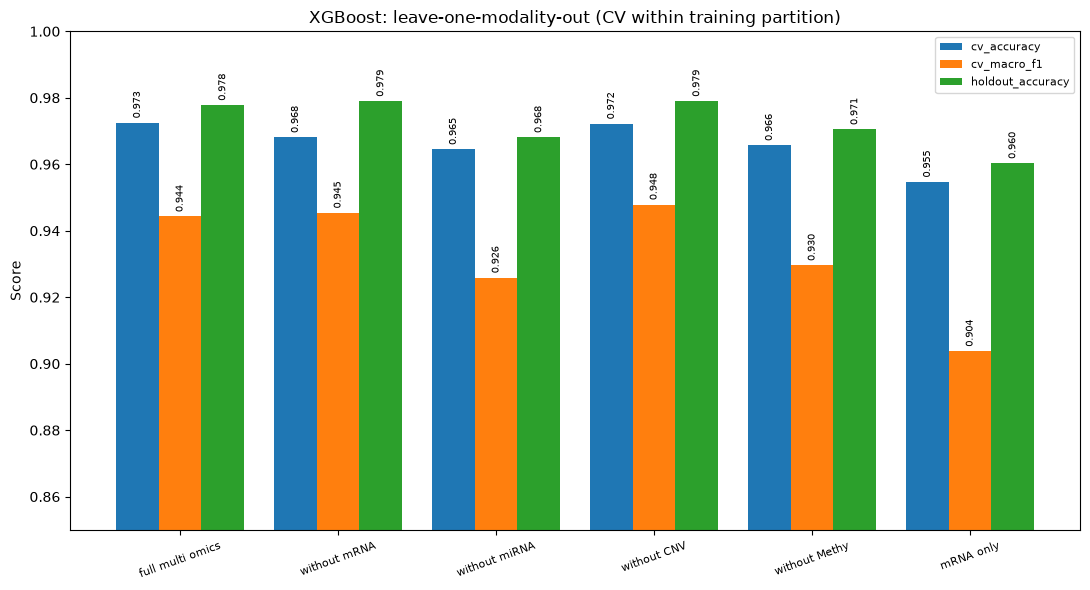


Saved D:\ICBEA-2027-PanCancer-MultiOmics\results\figures\ablation_barplot.png


In [17]:
from sklearn.metrics import precision_score, f1_score, accuracy_score, cohen_kappa_score

# ---------------------------------------------------------------------------
# RUNTIME NOTE
# The leave-one-modality-out ablation retrains XGBoost 6 configurations x
# (1 holdout + 5 CV folds) on 9,844 features, which costs well over an hour.
# The full implementation is `src/revision_experiments.py` (point estimates) and
# `src/revision_ablation_uncertainty.py` (25-fold paired uncertainty).
# Here we load those saved results and visualise them, so the notebook stays
# runnable end-to-end and its numbers agree with results/statistical_analysis/.
# ---------------------------------------------------------------------------
import pathlib
_REPO = pathlib.Path.cwd()
if not (_REPO / "results").exists() and (_REPO.parent / "results").exists():
    _REPO = _REPO.parent
RES = _REPO / "results"
RES.mkdir(parents=True, exist_ok=True)

abl_path = RES / "statistical_analysis" / "ablation_point_estimates.csv"
assert abl_path.exists(), f"{abl_path} not found (run src/revision_experiments.py first)"
abl = pd.read_csv(abl_path)
print(abl.to_string(index=False))

unc_path = RES / "statistical_analysis" / "ablation_paired_uncertainty.csv"
if unc_path.exists():
    unc = pd.read_csv(unc_path)
    print("\nPaired differences vs the full model (25 folds, Nadeau-Bengio corrected):")
    print(unc[["comparison", "metric", "mean_delta", "ci95_NB", "p_NB_2s", "significant_5pct"]].to_string(index=False))
    print("\nOnly the mRNA-only configuration differs significantly from the full model.")
else:
    print("\n(paired uncertainty file not found; run src/revision_ablation_uncertainty.py)")

xx = np.arange(len(abl)); w = 0.27
fig, ax = plt.subplots(figsize=(11, 6))
for i, met in enumerate(["cv_accuracy", "cv_macro_f1", "holdout_accuracy"]):
    vals = abl[met].astype(float).values
    ax.bar(xx + (i - 1) * w, vals, w, label=met)
    for xi, v in zip(xx + (i - 1) * w, vals):
        ax.text(xi, v + 0.002, f"{v:.3f}", ha="center", fontsize=7, rotation=90)
ax.set_xticks(xx)
ax.set_xticklabels([c.replace("_", " ") for c in abl["configuration"]], fontsize=8, rotation=20)
ax.set_ylim(0.85, 1.0); ax.set_ylabel("Score"); ax.legend(fontsize=8)
ax.set_title("XGBoost: leave-one-modality-out (CV within training partition)")
plt.tight_layout()
(RES / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(RES / "figures" / "ablation_barplot.png", dpi=300, bbox_inches="tight")
plt.show()
print("\nSaved", RES / "figures" / "ablation_barplot.png")


### 10d. Class 0–31 → TCGA project code → cancer name

Labels are integers only; the repo has no name mapping. Every sample id is a TCGA barcode,
so the project code is recovered data-driven. Documentation artifact, not an ML experiment.

In [18]:
import sys, pathlib
# make src/ importable whether we run from repo root or from notebooks/
for _p in (pathlib.Path.cwd() / 'src', pathlib.Path.cwd().parent / 'src'):
    if _p.exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
"""Class 0-31 -> TCGA project -> cancer name (data-driven from TCGA barcodes)."""
from common import TSS_PROJECT, TCGA_PROJECT_NAMES, tcga_project_code

class_rows = []
for cls in sorted(y.unique()):
    idx = y[y == cls].index
    codes = [tcga_project_code(s) for s in idx]
    dom = max(set(codes), key=codes.count)
    project = TSS_PROJECT.get(dom, "UNKNOWN")
    class_rows.append({
        "class": int(cls),
        "n_samples": len(idx),
        "dominant_tss_code": dom,
        "tcga_code": project,
        "cancer_name": TCGA_PROJECT_NAMES.get(project, "Unknown"),
    })
mapping = pd.DataFrame(class_rows)
mapping.to_csv("class_mapping_0_31.csv", index=False)
print("Saved class_mapping_0_31.csv")
mapping

Saved class_mapping_0_31.csv


,class,n_samples,dominant_tss_code,tcga_code,cancer_name
0,0,76,OR,ACC,Adrenocortical carcinoma
1,1,401,DK,BLCA,Bladder urothelial carcinoma
2,2,757,BH,BRCA,Breast invasive carcinoma
3,3,291,C5,CESC,Cervical squamous cell carcinoma
4,4,36,W5,CHOL,Cholangiocarcinoma
5,5,285,A6,COAD,Colon adenocarcinoma
6,6,47,FF,DLBC,"Lymphoid neoplasm, diffuse large B-cell lymphoma"
7,7,180,L5,ESCA,Esophageal carcinoma
8,8,506,CV,HNSC,Head and neck squamous cell carcinoma
9,9,65,KL,KICH,Kidney chromophobe
